# Name : Muhammad Danish Zaheer Awan
# REG id : 25280092
# Task 2 PPO 

## Shared Setup 

In [1]:
import os
import sys
from pathlib import Path

In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in candidates if (path / 'configs' / 'ppo.yaml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import torch
from IPython.display import display, Image

from common.data import load_yaml, read_jsonl, repo_path
from task2_ppo.analysis.aggregate import (
    clipping_tables, kl_summary_table, standard_summary_table,
)
from task2_ppo.analysis.plots import save_task2_figures
from task2_ppo.core.protocol import validate_shared_protocol

CONFIG_PATH = 'configs/ppo.yaml'
OVERWRITE = False
config = load_yaml(CONFIG_PATH)
validate_shared_protocol(config)
pd.set_option('display.max_colwidth', 300)
print('Project root:', PROJECT_ROOT)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Project root: c:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


In [3]:
# Model download/cache block. Reruns reuse the Hugging Face cache.
from huggingface_hub import snapshot_download

for model_id in [config['base_model'], config['reward_model']]:
    local_path = snapshot_download(repo_id=model_id)
    print(f'{model_id} is ready at {local_path}')

c:\Users\DanishZaheer\anaconda3\envs\ATML\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 2002.72it/s]


Qwen/Qwen2.5-1.5B-Instruct is ready at C:\Users\DanishZaheer\.cache\huggingface\hub\models--Qwen--Qwen2.5-1.5B-Instruct\snapshots\989aa7980e4cf806f80c7fef2b1adb7bc71aa306


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 580.16it/s]

yavuz-ai/qwen2.5-1.5b-rm-ultrafeedback is ready at C:\Users\DanishZaheer\.cache\huggingface\hub\models--yavuz-ai--qwen2.5-1.5b-rm-ultrafeedback\snapshots\f98759a4a1ccdc47a3136748b6bfea9a32ba8fcc


In [4]:
# Check the exact released inputs before starting an expensive run.
required_paths = {
    'policy midpoint': repo_path(config['paths']['ppo_midpoint_policy']),
    'critic midpoint': repo_path(config['paths']['ppo_midpoint_value']),
    'cached rollout': repo_path(config['cached_rollouts']),
    'training prompts': repo_path(config['paths']['rl_prompt_train']),
    'evaluation prompts': repo_path(config['paths']['rl_prompt_eval']),
}
for label, path in required_paths.items():
    if not path.exists():
        raise FileNotFoundError(f'Missing {label}: {path}')
    print(f'OK: {label} -> {path}')

train_rows = read_jsonl(config['paths']['rl_prompt_train'])
eval_rows = read_jsonl(config['paths']['rl_prompt_eval'])
assert len(train_rows) == 1200
assert len(eval_rows) == 200
print('Training prompts:', len(train_rows), '| Held-out prompts:', len(eval_rows))

OK: policy midpoint -> C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\checkpoints\ppo_midpoint_policy
OK: critic midpoint -> C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\checkpoints\ppo_midpoint_value
OK: cached rollout -> C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\cached\ppo_rollout.pt
OK: training prompts -> C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\data\rl_prompt_pool_train.jsonl
OK: evaluation prompts -> C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\data\rl_prompt_pool_eval.jsonl
Training prompts: 1200 | Held-out prompts: 200


## Task 2 Part 1

In [5]:
from task2_ppo.continue_train import run_ppo

standard_training = run_ppo(
    CONFIG_PATH, run_name='standard', overwrite=OVERWRITE
)
display(pd.DataFrame([standard_training]))

Using completed standard PPO continuation.


,run_name,updates,prompts_per_update,ppo_epochs,clip_epsilon,kl_beta,training_reward_device,training_reward_quantized,seed,generated_tokens,maximum_generation_budget,wall_time_seconds,peak_vram_gib,policy_directory,value_directory,policy_sha256,value_sha256
0,standard,20,1,2,0.2,0.1,cpu,False,6304,6622,10240,845.993717,4.784283,C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\outputs\standard\policy,C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\outputs\standard\value,c09b857e1e17681b1da31b2a2f610314c3996e6d42e172919ac1be0de151e7be,ef41c56c2612d6a30cd52ea0e5eb3ad77352974cdab8f5ae09014956ae8fa8d9


Using completed standard held-out evaluation.


,run,updates,maximum_generation_budget,generated_tokens,clip_epsilon,kl_beta,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,peak_vram_gib,wall_time_seconds
0,standard,20,10240,6622,0.2,0.1,1.706122,-0.000023,0.999116,286.145,4.784283,845.993717


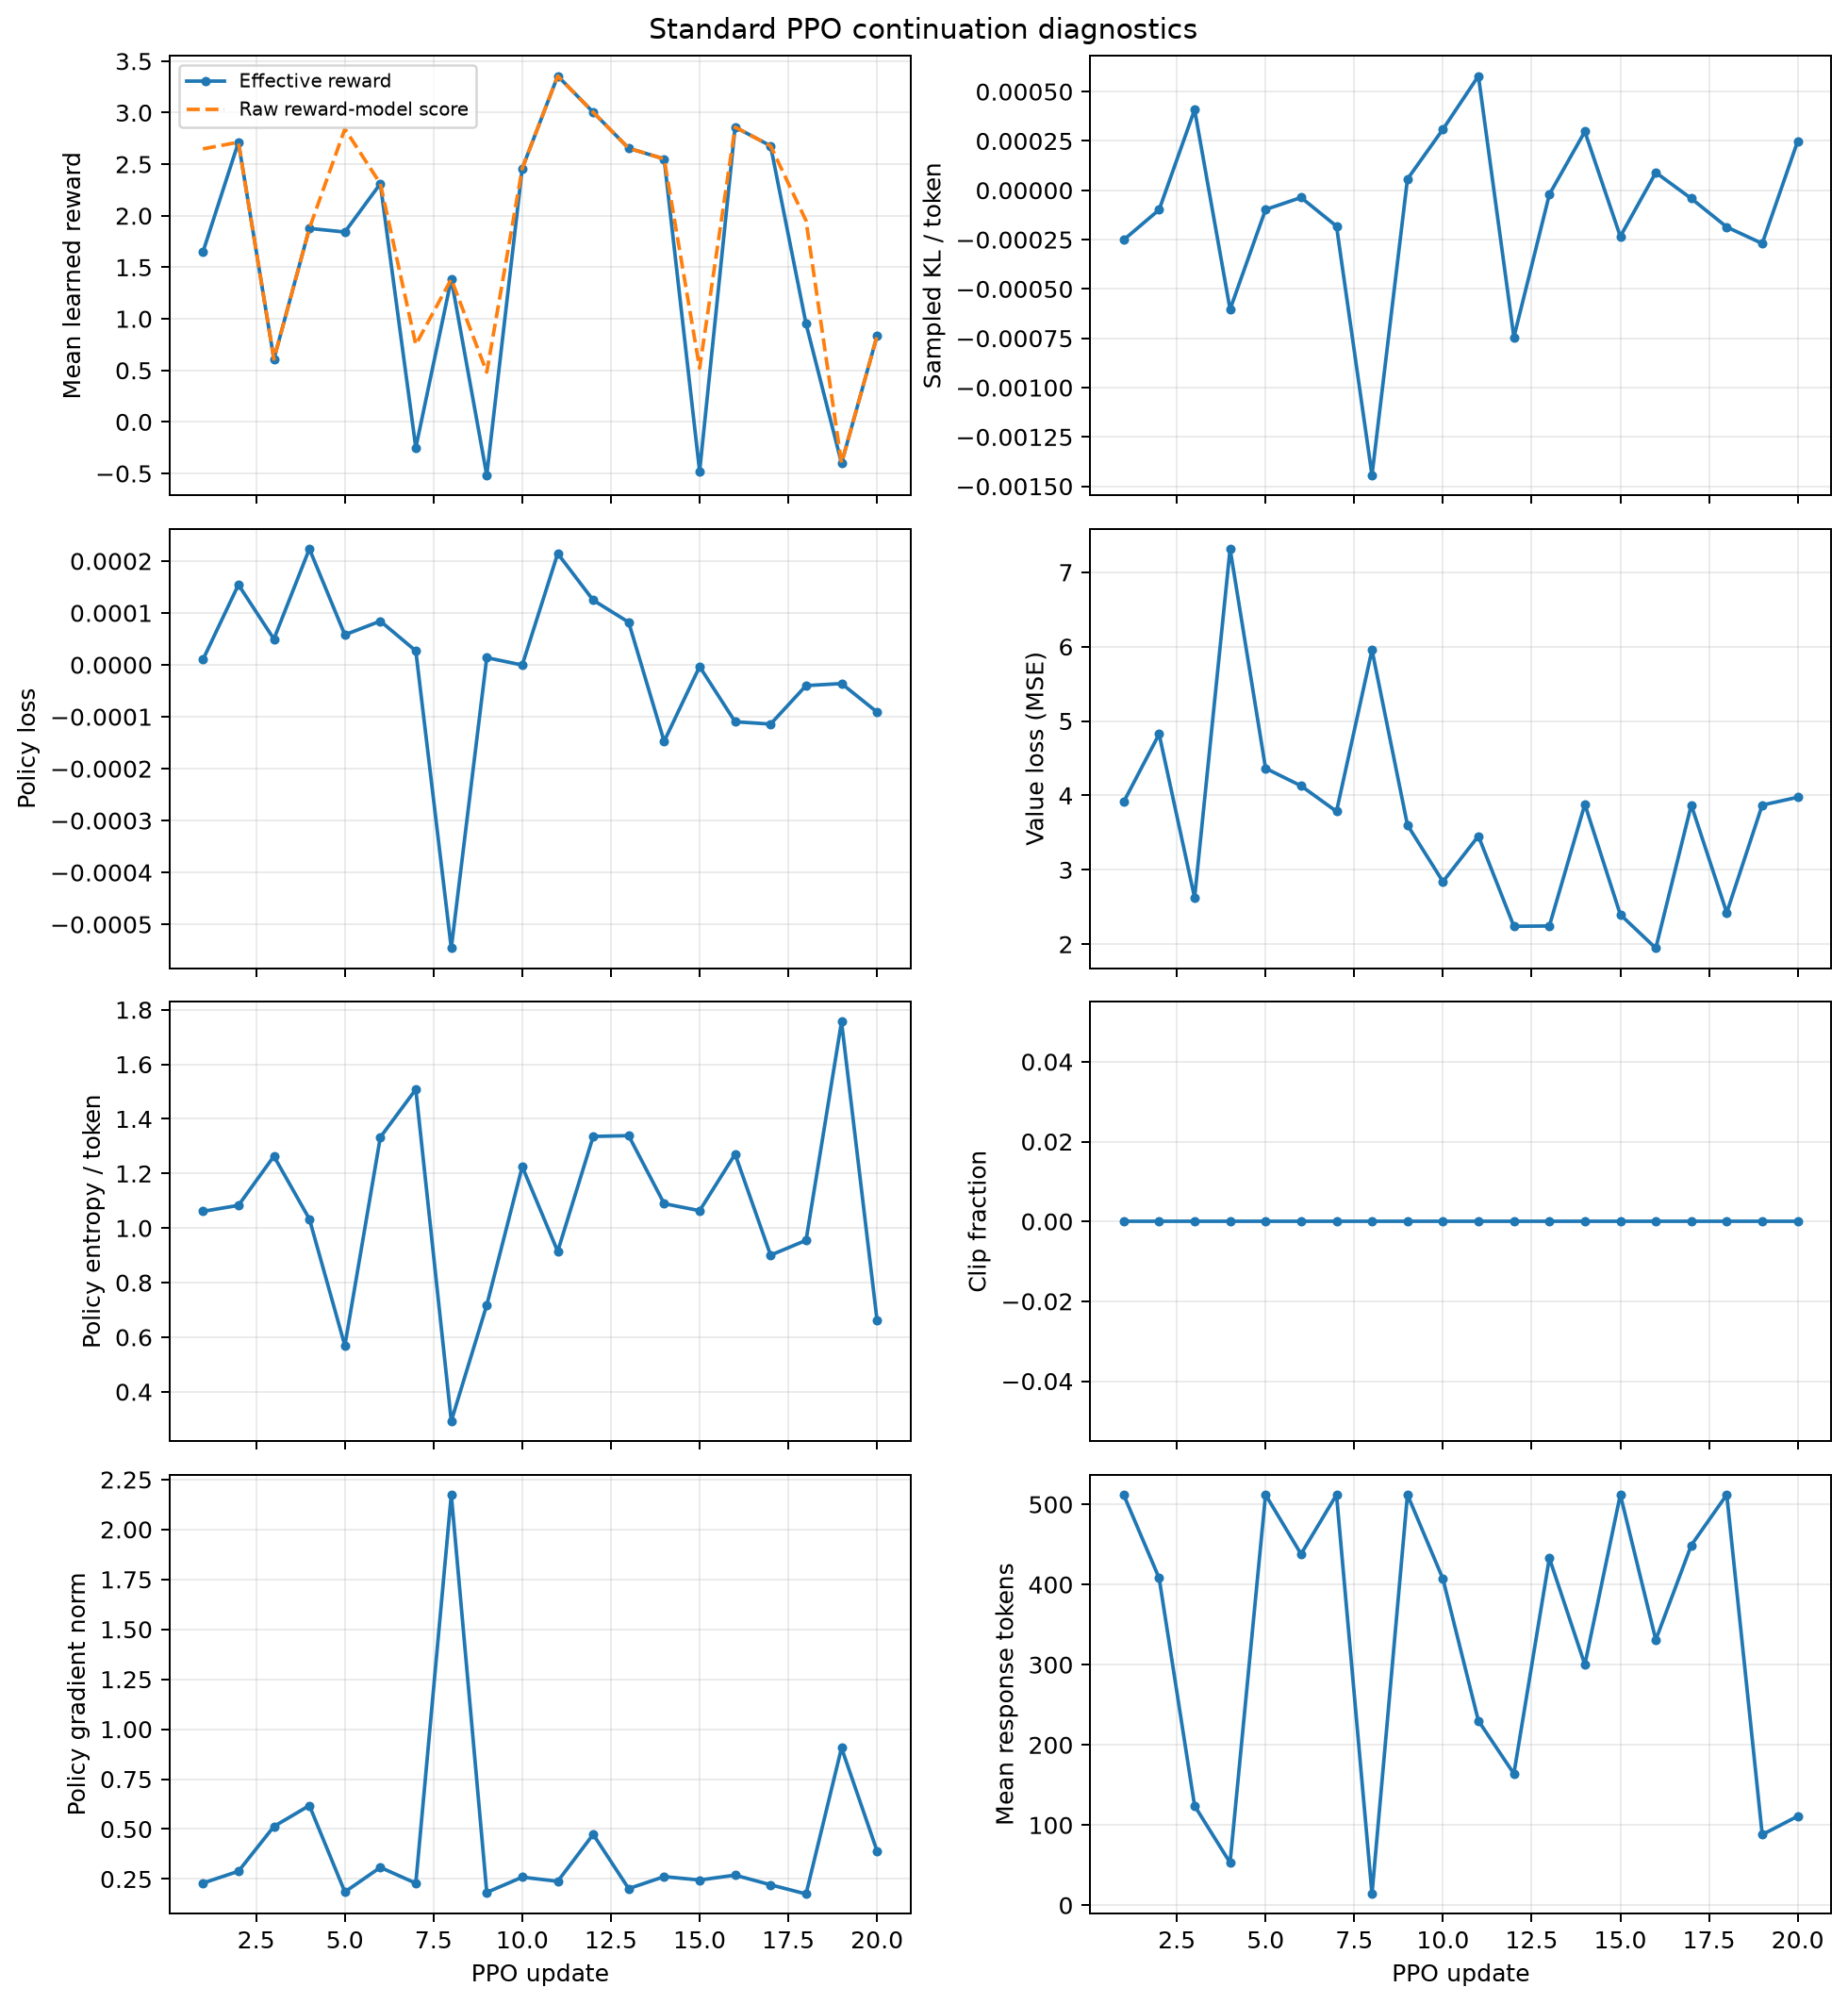

In [6]:
from task2_ppo.evaluate import run_evaluation

standard_evaluation = run_evaluation(
    CONFIG_PATH, name='standard', overwrite=OVERWRITE
)
save_task2_figures(config['results_dir'])
display(standard_summary_table(config['results_dir']))
display(Image(filename=str(repo_path(config['results_dir']) / 'figures' / 'standard_trajectories.png')))

In [7]:
# Shortlist for later manual reward-versus-quality inspection.
standard_examples = pd.DataFrame(
    read_jsonl(repo_path(config['results_dir']) / 'standard' / 'qualitative_candidates.jsonl')
)
display(standard_examples[['candidate_reason', 'prompt', 'response', 'reward_model_score', 'sampled_kl_token_mean', 'response_length']].head(12))

,candidate_reason,prompt,response,reward_model_score,sampled_kl_token_mean,response_length
0,high_reward,"Given the matrix as A = [2 -3; 5 6], find the determinant","To find the determinant of the given matrix \( A \), we can use the formula for the determinant of a 2x2 matrix. For a matrix:\n\n\[\nA = \begin{bmatrix}\na & b \\\nc & d\n\end{bmatrix}\n\]\n\nThe determinant is calculated as:\n\n\[\n\det(A) = ad - bc\n\]\n\nFor the given matrix \( A = \begin{bm...",4.250000,0.000197,208
1,high_reward,what is the error loss funciton of an adaline model?,The Adaline (Adaptive Linear Neuron) algorithm is a type of linear classifier that uses a single-layer neural network with one input and one output neuron. The goal of Adaline is to minimize the squared error between the predicted outputs and the actual target values.\n\nThe error function for A...,4.031250,-0.000215,218
2,high_reward,B.1 CONCEPT CHECK-UP QUESTIONS\n1. What does the protoplasm of a cell include?\n2. a. What feature of cell membranes controls the movement of materials in and out of a cell?\nb. What determines the presence of the features in 2. a?\n3. a. What cell components are required to make proteins?\nb. W...,"Sure, let's go through each question step-by-step:\n\n### Question 1: What does the protoplasm of a cell include?\n\n**Answer:** The protoplasm of a cell includes all the material that is not part of the nucleus. It consists of:\n- Cytoplasm (the jelly-like substance within the cell)\n- Organell...",3.931641,-0.000080,654
3,high_reward,"Data format:\nYou must have [ HTML page ] data type and [ HTML page ] code type in the following Rewrite prompt\nRewrite prompt:\nHow can you create a web page that displays an image with a caption underneath it? Use HTML and CSS to accomplish this task. Additionally, make the image a hyperlink ...","To achieve the desired effect of displaying an image with a caption underneath it using HTML and CSS, you can follow these steps:\n\n1. Create a basic HTML structure that includes a `div` element with an ID of `img-container`.\n2. Within this `div`, include an `<a>` tag for the image link and an...",3.871094,0.000118,633
4,high_reward,"Premise: ""An older gentleman is stoking a fire.""\nHypothesis: ""The man is pouring water on the fire.""\nIs the hypothesis entailed by the premise?\nOptions:\n- yes\n- it is not possible to tell\n- no Now, let's be accurate as possible. Some thinking first:","To determine if the hypothesis is entailed by the premise, we need to analyze whether the information in the hypothesis can be logically derived from or necessarily follows from the information given in the premise.\n\n**Premise:** ""An older gentleman is stoking a fire.""\n\n**Hypothesis:** ""The ...",3.867188,-0.000413,304
5,high_reward,"Hi, can you make a one programming task for me? \n\nI need a PHP custom function ""smart\_sort\_array"", which accepts arguments ""set"" and ""order"". The function needs to go through elements of the array ""set"". Where each element of the array ""set"" is also an associative sub-array with keys ""name"",...","Certainly! Below is a PHP code snippet that defines a custom function `smart_sort_array` as per your requirements:\n\n```php\n<?php\n\nfunction smart_sort_array($set, $order) {\n // Define the comparison function based on the order parameter\n switch ($order) {\n case 'asc':\n ...",3.564453,-0.000002,620
6,high_reward,"In at least 500 words, provide a comprehensive analysis of how pesticides affect different types of wildlife, including their long-term effects on the ecosystem. In addition, suggest at least three sustainable alternatives to pesticide use for pest control in agricultural and residential setting...","Pesticides have been used extensively in agriculture for decades as a means of controlling pests and weeds. However, these chemicals can have significant impacts on various species within ecosystems, particularly those that are sensitive or endangered. This analysis will explore the ef

## Task 2 Part 2

In [8]:
from task2_ppo.analyze_clipping import run_clipping_study

clipping_summary = run_clipping_study(
    CONFIG_PATH, overwrite=OVERWRITE
)
display(clipping_summary)

Using completed cached-rollout clipping analysis.
Using completed clip_eps_0.05 PPO continuation.
Using completed clip_eps_0.05 held-out evaluation.
Using completed clip_eps_0.20 PPO continuation.
Using completed clip_eps_0.20 held-out evaluation.
Using completed clip_eps_0.50 PPO continuation.
Using completed clip_eps_0.50 held-out evaluation.


,run,clip_epsilon,updates,maximum_generation_budget,generated_tokens,cached_clipped_surrogate,cached_clip_fraction,cached_affected_token_fraction,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,policy_loss_std,policy_gradient_norm_std,reward_step_change_std,finite_metric_fraction
0,clip_eps_0.05,0.05,8,4096,2573,-0.015059,0.167234,0.081007,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0
1,clip_eps_0.20,0.20,8,4096,2573,-0.010964,0.055820,0.026662,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0
2,clip_eps_0.50,0.50,8,4096,2573,-0.007211,0.030179,0.014409,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0


,clip_epsilon,cached_responses,cached_response_tokens,clipped_surrogate,clip_fraction,affected_token_fraction,ratio_mean,ratio_std,ratio_min,ratio_max
0,0.05,32,8814,-0.015059,0.167234,0.081007,0.999326,0.519282,2.009196e-08,32.802502
1,0.20,32,8814,-0.010964,0.055820,0.026662,0.999326,0.519282,2.009196e-08,32.802502
2,0.50,32,8814,-0.007211,0.030179,0.014409,0.999326,0.519282,2.009196e-08,32.802502


,run,clip_epsilon,updates,maximum_generation_budget,generated_tokens,cached_clipped_surrogate,cached_clip_fraction,cached_affected_token_fraction,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,policy_loss_std,policy_gradient_norm_std,reward_step_change_std,finite_metric_fraction
0,clip_eps_0.05,0.05,8,4096,2573,-0.015059,0.167234,0.081007,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0
1,clip_eps_0.20,0.20,8,4096,2573,-0.010964,0.055820,0.026662,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0
2,clip_eps_0.50,0.50,8,4096,2573,-0.007211,0.030179,0.014409,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0


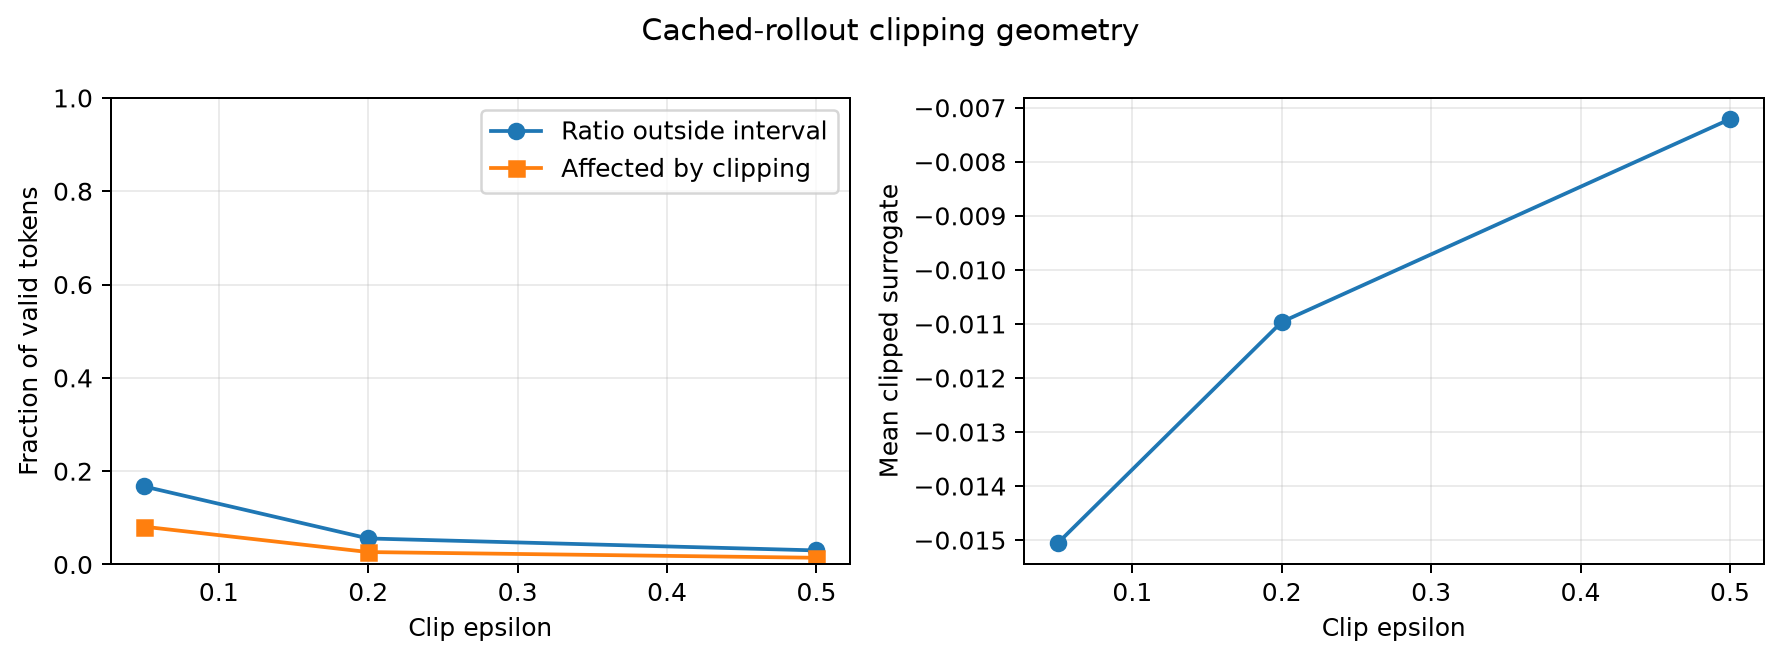

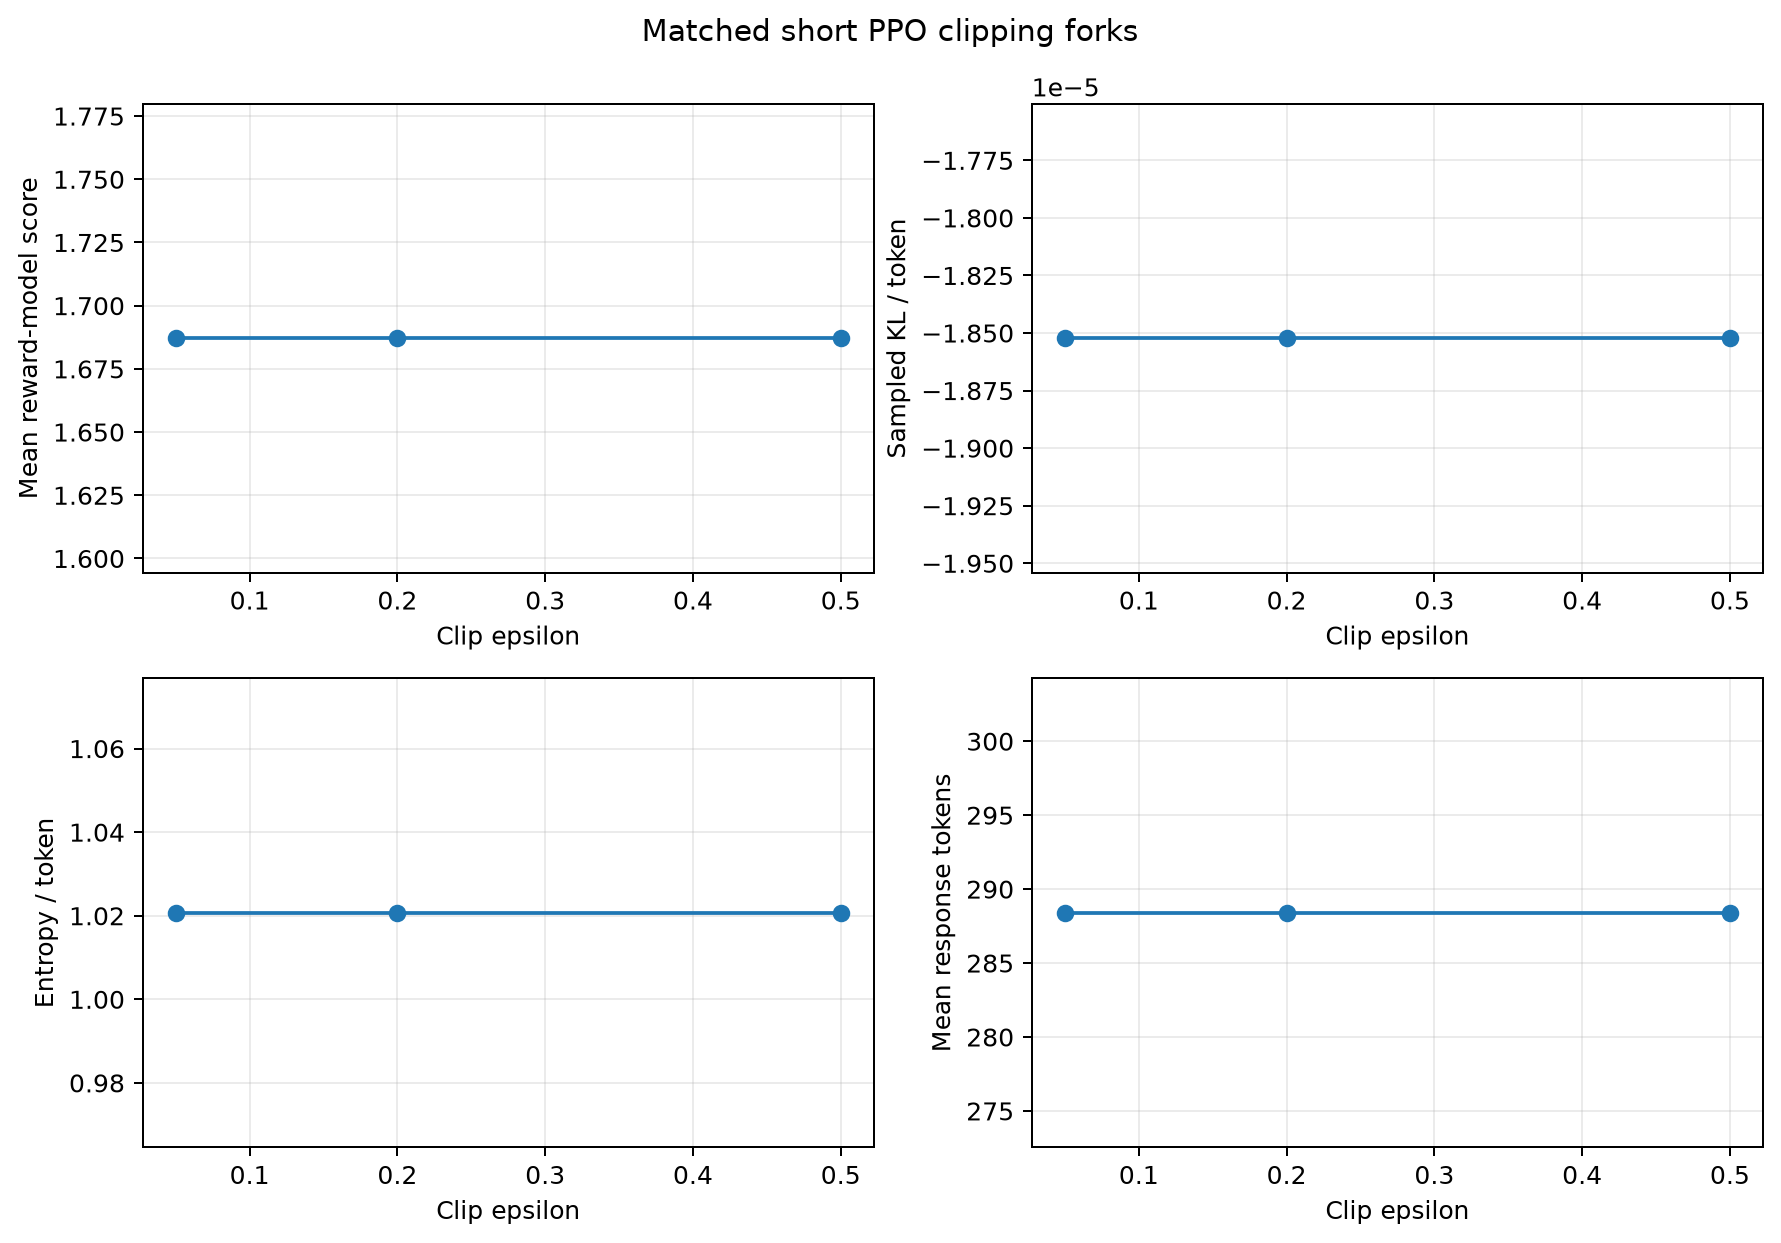

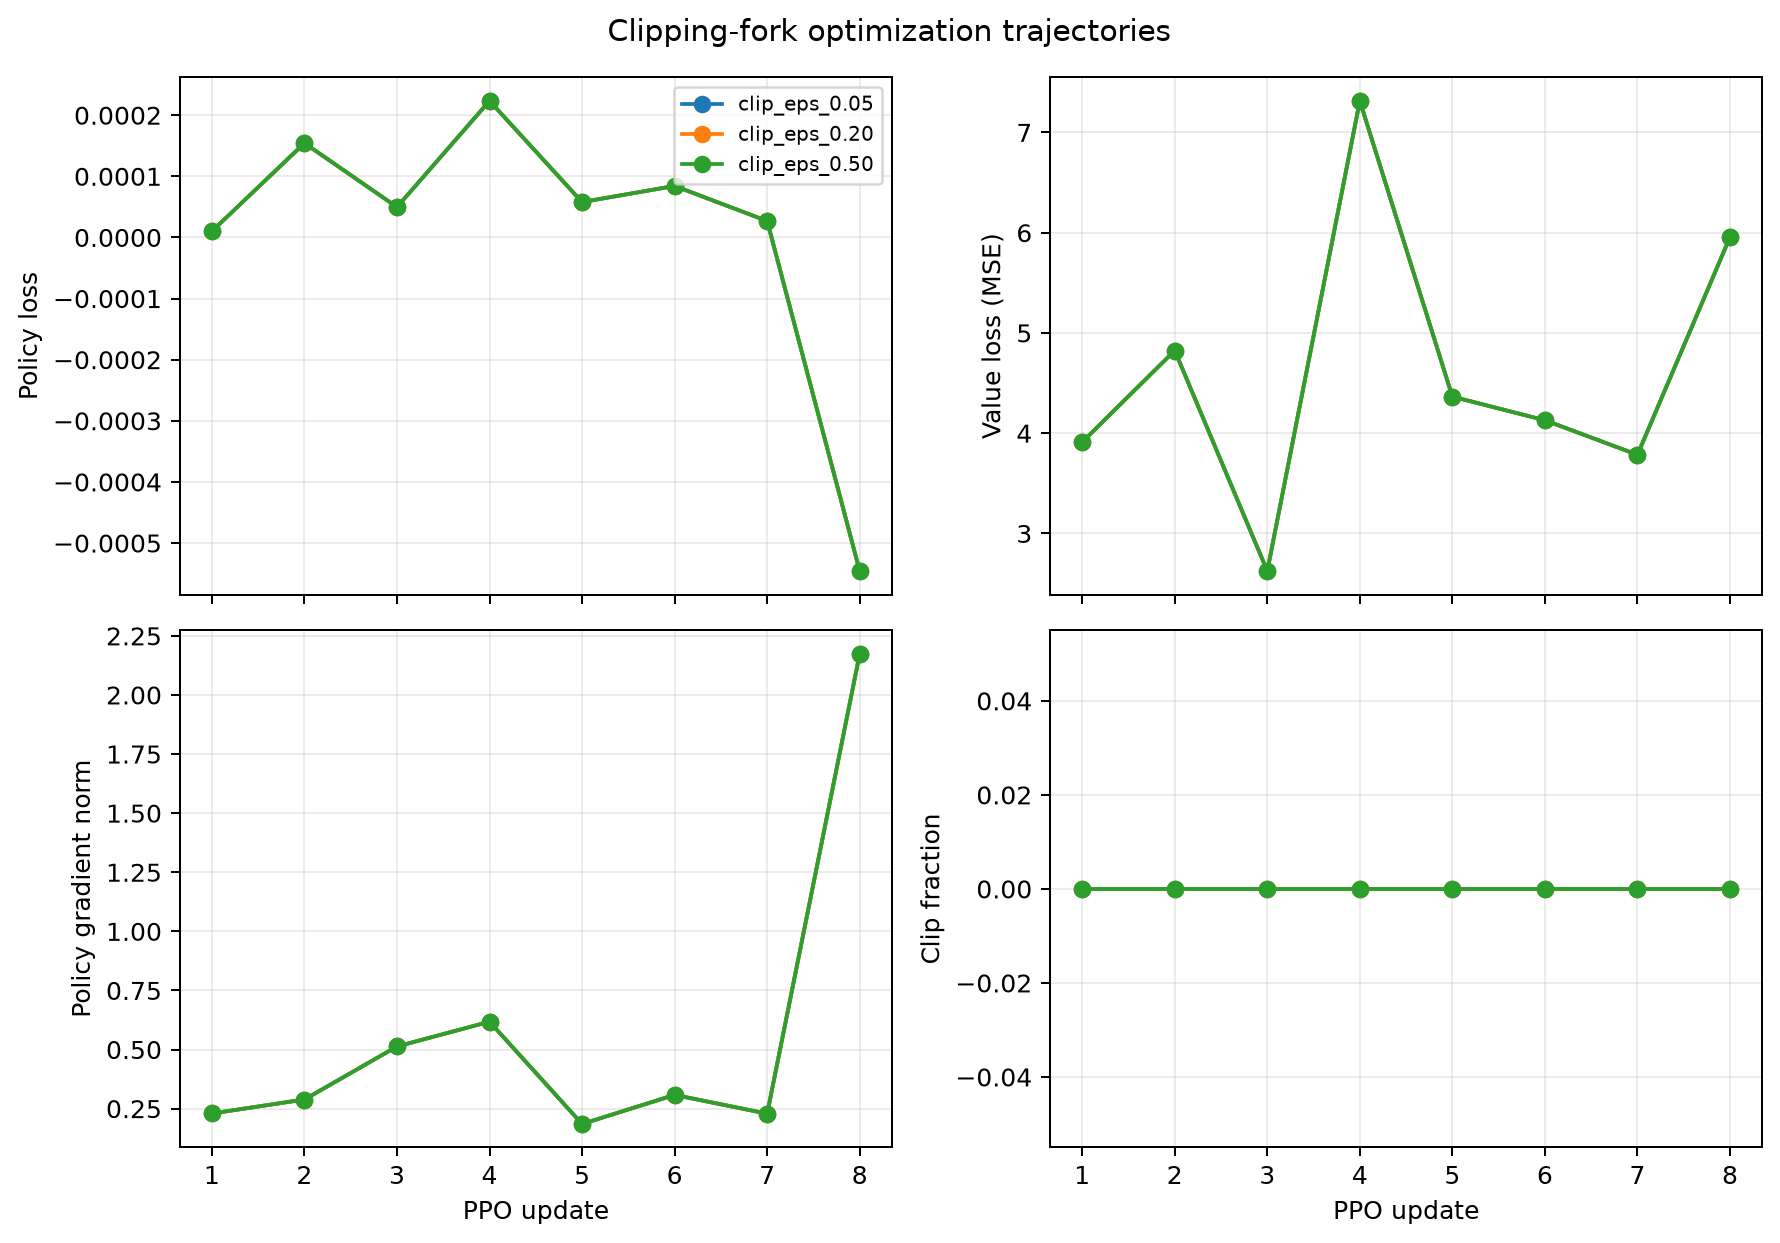

In [9]:
cached_clipping, clipping_forks = clipping_tables(config['results_dir'])
display(cached_clipping)
display(clipping_forks)
for filename in ['cached_clipping.png', 'clipping_forks.png', 'clipping_trajectories.png']:
    display(Image(filename=str(repo_path(config['results_dir']) / 'figures' / filename)))

## Task 2 Part 3

In [10]:
from task2_ppo.ablate_kl import run_kl_study

kl_summary = run_kl_study(CONFIG_PATH, overwrite=OVERWRITE)

display(kl_summary)

Using completed kl_beta_0.00 PPO continuation.
Using completed kl_beta_0.00 held-out evaluation.
Using completed kl_beta_0.10 PPO continuation.
Using completed kl_beta_0.10 held-out evaluation.
Using completed kl_beta_0.20 PPO continuation.
Using completed kl_beta_0.20 held-out evaluation.


,run,kl_beta,updates,maximum_generation_budget,generated_tokens,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,policy_loss_std,policy_gradient_norm_std,reward_step_change_std,finite_metric_fraction
0,kl_beta_0.00,0.0,8,4096,2573,1.701126,-0.000042,0.999394,285.290,0.000367,0.619126,1.421579,1.0
1,kl_beta_0.10,0.1,8,4096,2573,1.687024,-0.000019,1.020677,288.390,0.000219,0.623169,1.540495,1.0
2,kl_beta_0.20,0.2,8,4096,2647,1.700574,-0.000011,0.997436,283.325,0.000300,0.641150,1.482956,1.0


,run,kl_beta,updates,maximum_generation_budget,generated_tokens,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,policy_loss_std,policy_gradient_norm_std,reward_step_change_std,finite_metric_fraction
0,kl_beta_0.00,0.0,8,4096,2573,1.701126,-0.000042,0.999394,285.290,0.000367,0.619126,1.421579,1.0
1,kl_beta_0.10,0.1,8,4096,2573,1.687024,-0.000019,1.020677,288.390,0.000219,0.623169,1.540495,1.0
2,kl_beta_0.20,0.2,8,4096,2647,1.700574,-0.000011,0.997436,283.325,0.000300,0.641150,1.482956,1.0


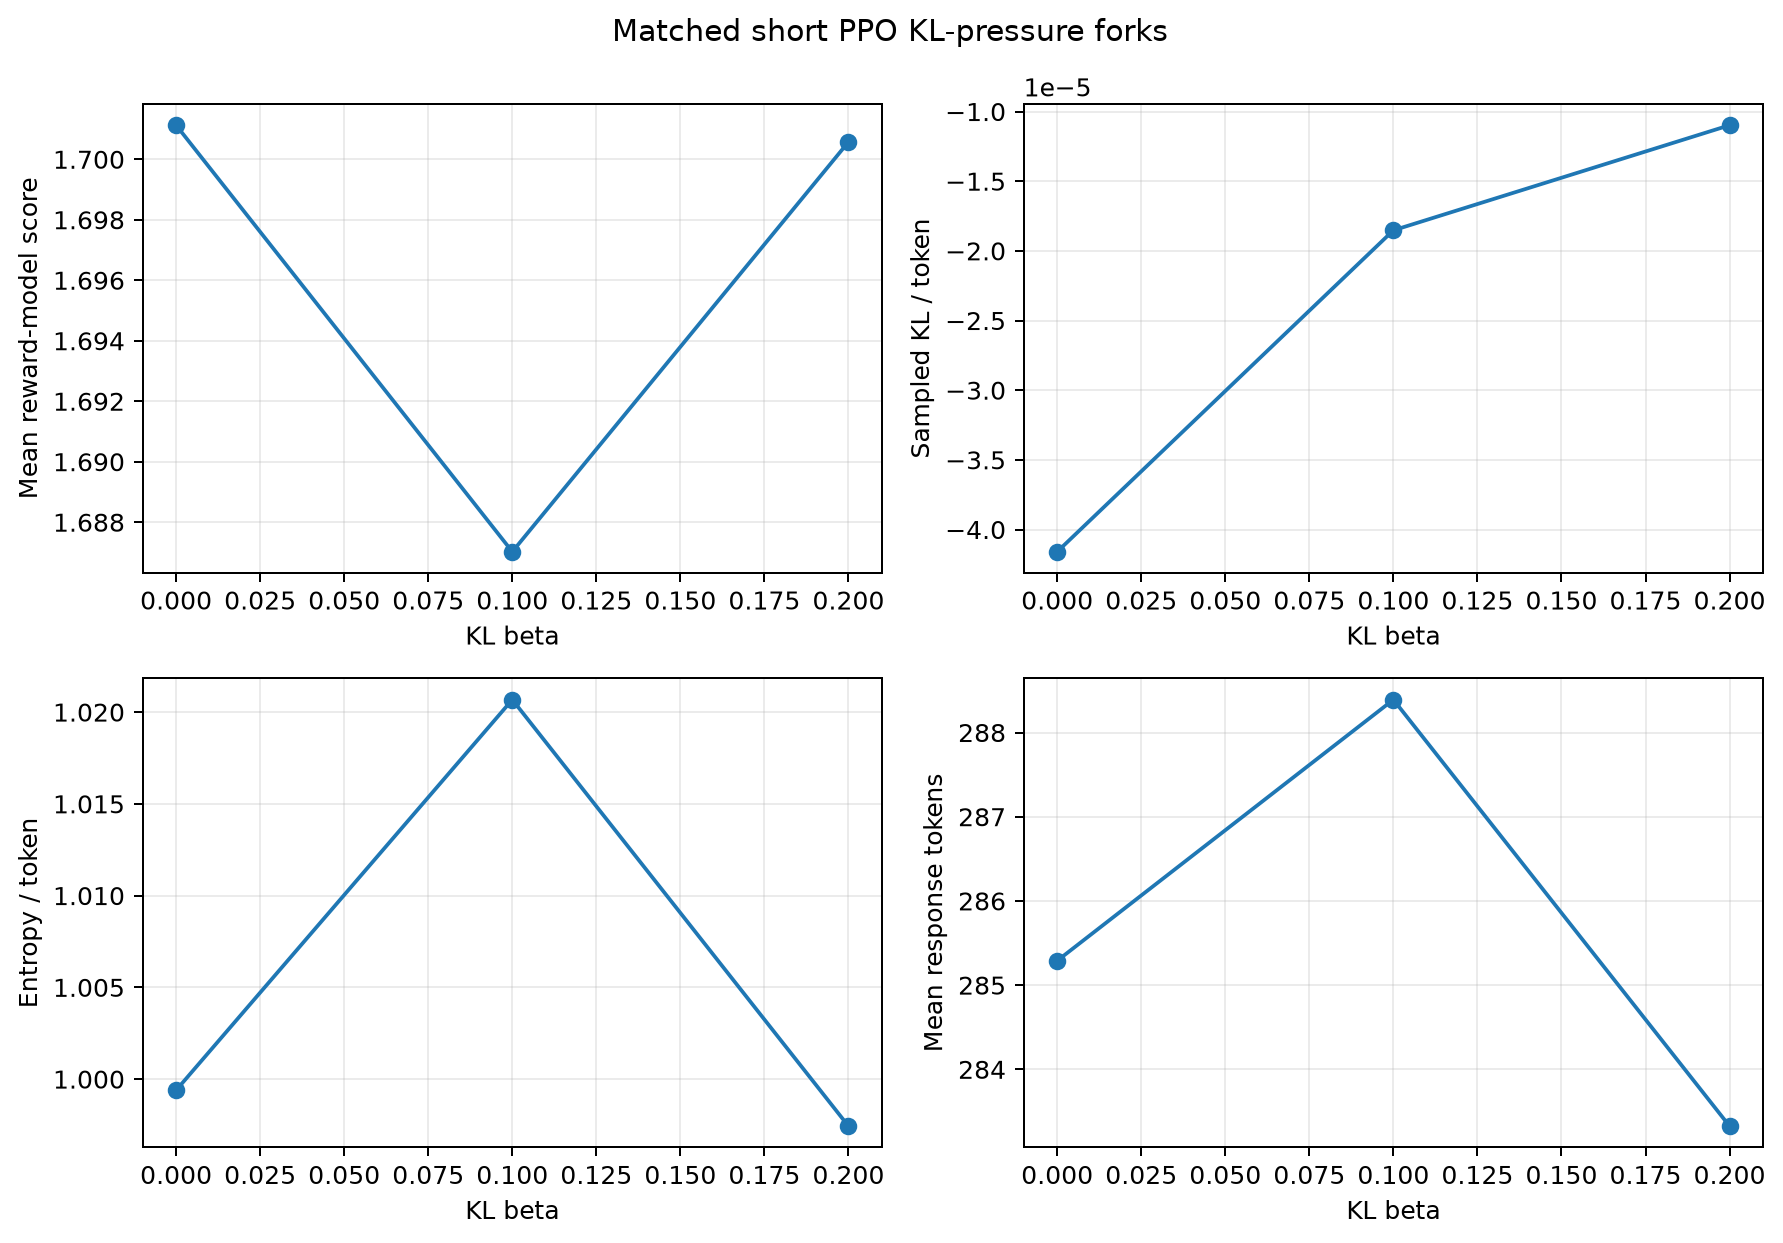

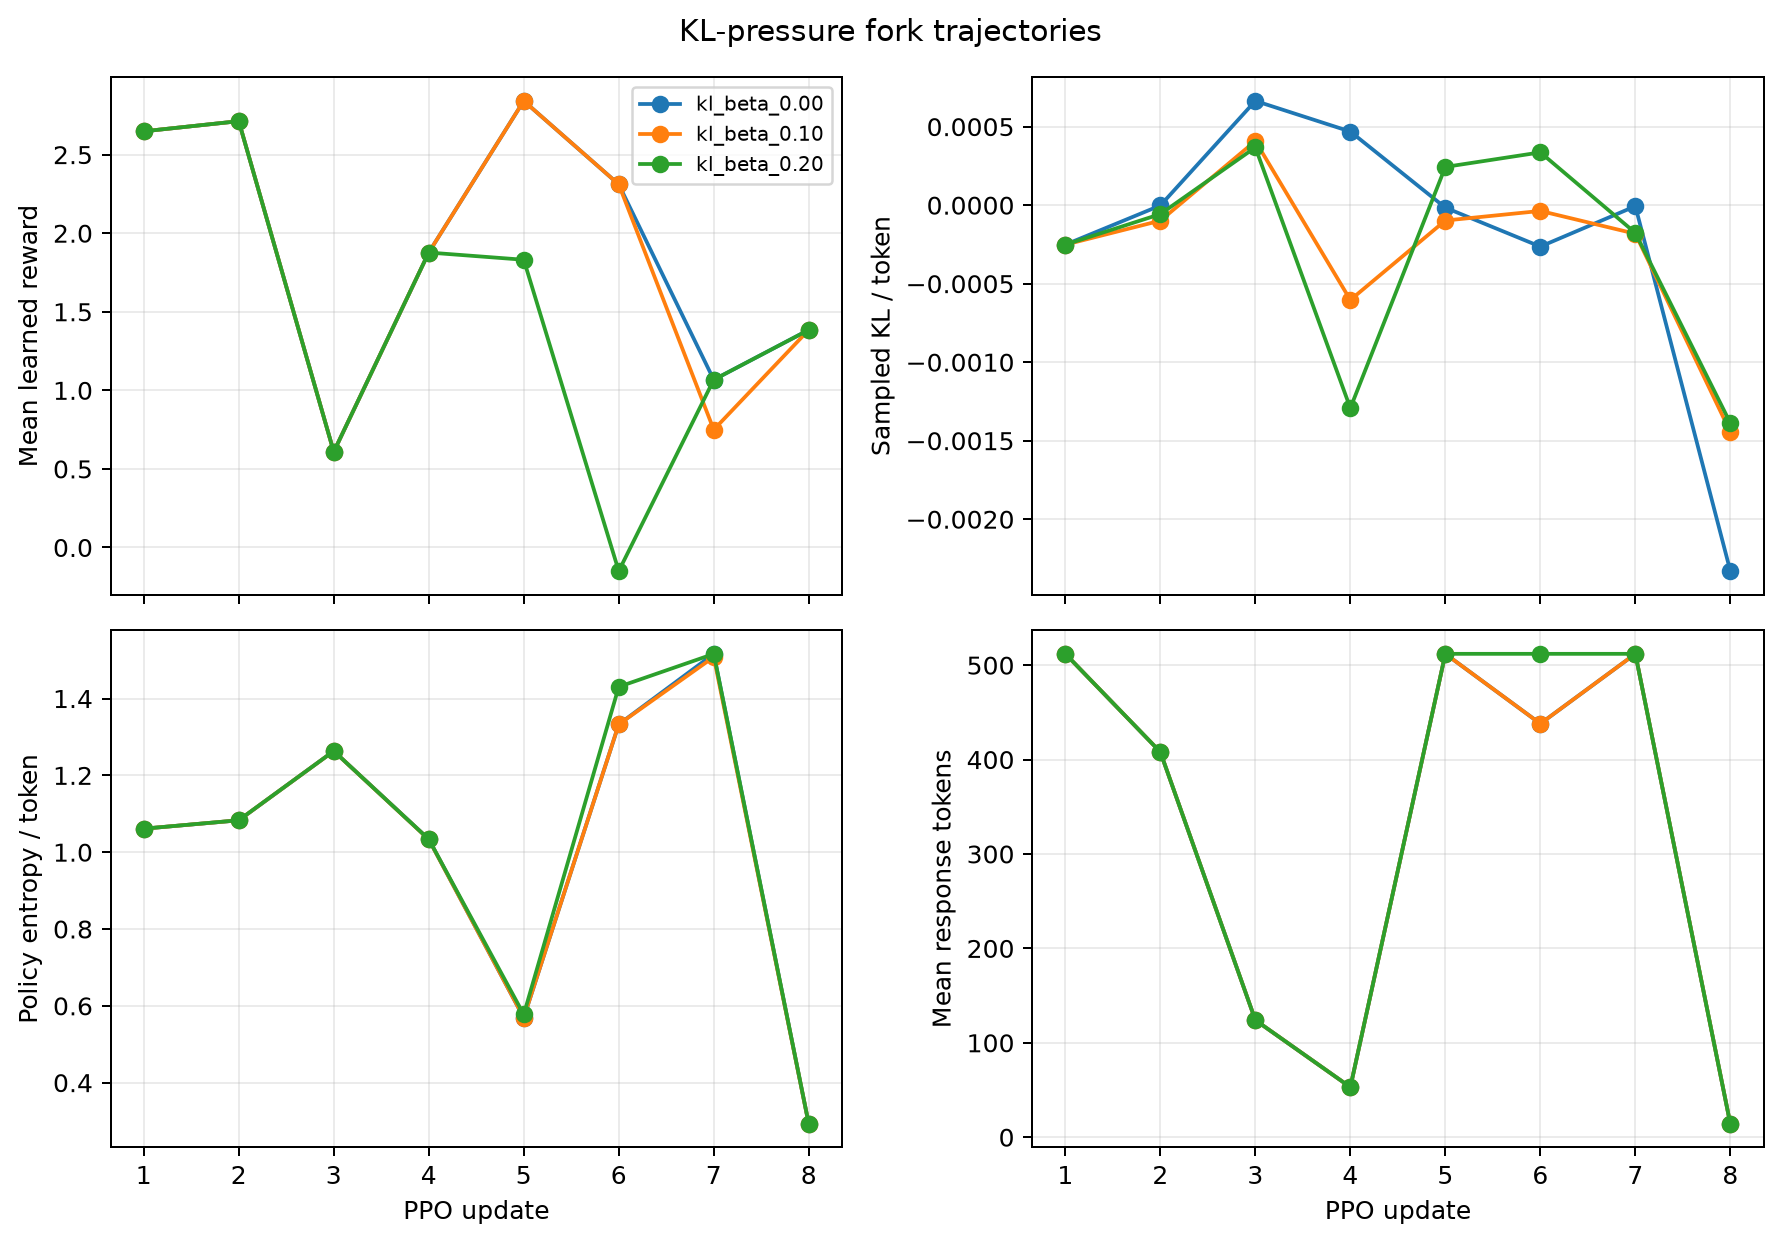

In [11]:
display(kl_summary_table(config['results_dir']))
for filename in ['kl_forks.png', 'kl_trajectories.png']:
    display(Image(filename=str(repo_path(config['results_dir']) / 'figures' / filename)))

## Research questions

In [12]:
# Complete quantitative evidence bundle for the report.
saved_figures = save_task2_figures(config['results_dir'])
display(standard_summary_table(config['results_dir']))
cached_clipping, clipping_forks = clipping_tables(config['results_dir'])
display(cached_clipping)
display(clipping_forks)
display(kl_summary_table(config['results_dir']))
print('Saved figures:')
for name, path in saved_figures.items():
    print(f'  {name}: {path}')

,run,updates,maximum_generation_budget,generated_tokens,clip_epsilon,kl_beta,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,peak_vram_gib,wall_time_seconds
0,standard,20,10240,6622,0.2,0.1,1.706122,-0.000023,0.999116,286.145,4.784283,845.993717


,clip_epsilon,cached_responses,cached_response_tokens,clipped_surrogate,clip_fraction,affected_token_fraction,ratio_mean,ratio_std,ratio_min,ratio_max
0,0.05,32,8814,-0.015059,0.167234,0.081007,0.999326,0.519282,2.009196e-08,32.802502
1,0.20,32,8814,-0.010964,0.055820,0.026662,0.999326,0.519282,2.009196e-08,32.802502
2,0.50,32,8814,-0.007211,0.030179,0.014409,0.999326,0.519282,2.009196e-08,32.802502


,run,clip_epsilon,updates,maximum_generation_budget,generated_tokens,cached_clipped_surrogate,cached_clip_fraction,cached_affected_token_fraction,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,policy_loss_std,policy_gradient_norm_std,reward_step_change_std,finite_metric_fraction
0,clip_eps_0.05,0.05,8,4096,2573,-0.015059,0.167234,0.081007,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0
1,clip_eps_0.20,0.20,8,4096,2573,-0.010964,0.055820,0.026662,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0
2,clip_eps_0.50,0.50,8,4096,2573,-0.007211,0.030179,0.014409,1.687024,-0.000019,1.020677,288.39,0.000219,0.623169,1.540495,1.0


,run,kl_beta,updates,maximum_generation_budget,generated_tokens,heldout_reward,heldout_kl,heldout_entropy,heldout_response_length,policy_loss_std,policy_gradient_norm_std,reward_step_change_std,finite_metric_fraction
0,kl_beta_0.00,0.0,8,4096,2573,1.701126,-0.000042,0.999394,285.290,0.000367,0.619126,1.421579,1.0
1,kl_beta_0.10,0.1,8,4096,2573,1.687024,-0.000019,1.020677,288.390,0.000219,0.623169,1.540495,1.0
2,kl_beta_0.20,0.2,8,4096,2647,1.700574,-0.000011,0.997436,283.325,0.000300,0.641150,1.482956,1.0


Saved figures:
  standard_trajectories.png: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\results\figures\standard_trajectories.png
  cached_clipping.png: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\results\figures\cached_clipping.png
  clipping_forks.png: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\results\figures\clipping_forks.png
  clipping_trajectories.png: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\results\figures\clipping_trajectories.png
  kl_forks.png: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\results\figures\kl_forks.png
  kl_trajectories.png: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task2_ppo\results\figures\kl_trajectories.png


In [13]:
# Aligned responses for the required qualitative evidence. Judge quality manually.
def comparison_preview(path, limit=8):
    rows = read_jsonl(path)
    preview = []
    for row in rows[:limit]:
        for run_name, condition in row['conditions'].items():
            preview.append({
                'prompt_id': row['prompt_id'],
                'prompt': row['prompt'],
                'run': run_name,
                **condition,
            })
    return pd.DataFrame(preview)

clipping_examples = comparison_preview(
    repo_path(config['results_dir']) / 'clipping' / 'qualitative_comparison.jsonl'
)
kl_examples = comparison_preview(
    repo_path(config['results_dir']) / 'kl' / 'qualitative_comparison.jsonl'
)
print('Clipping candidates (ranked by reward-score spread):')
display(clipping_examples)
print('KL-pressure candidates (ranked by reward-score spread):')
display(kl_examples)

Clipping candidates (ranked by reward-score spread):


,prompt_id,prompt,run,response,reward_model_score,sampled_kl_token_mean,entropy_token_mean,response_length
0,d407599fef051a44d505c8439c3c6a6fb7d8fb6658384a4c391e9c2f2146f16d,"Claim: ""One can find Sarah Jessica Parker on the show The Sopranos.""\nIs the claim above correct, and can it be verified by human common sense and without a web search?\nOptions:\n- yes\n- no\nChain of thought and solution for this question is:",clip_eps_0.05,"To determine if the claim ""One can find Sarah Jessica Parker on the show The Sopranos"" is correct based solely on human common sense and without needing to verify it through a web search, we need to consider several factors:\n\n1. **Identify the Show**: The Sopranos is an American television ser...",2.580078,0.000247,0.911178,303
1,d407599fef051a44d505c8439c3c6a6fb7d8fb6658384a4c391e9c2f2146f16d,"Claim: ""One can find Sarah Jessica Parker on the show The Sopranos.""\nIs the claim above correct, and can it be verified by human common sense and without a web search?\nOptions:\n- yes\n- no\nChain of thought and solution for this question is:",clip_eps_0.20,"To determine if the claim ""One can find Sarah Jessica Parker on the show The Sopranos"" is correct based solely on human common sense and without needing to verify it through a web search, we need to consider several factors:\n\n1. **Identify the Show**: The Sopranos is an American television ser...",2.580078,0.000247,0.911178,303
2,d407599fef051a44d505c8439c3c6a6fb7d8fb6658384a4c391e9c2f2146f16d,"Claim: ""One can find Sarah Jessica Parker on the show The Sopranos.""\nIs the claim above correct, and can it be verified by human common sense and without a web search?\nOptions:\n- yes\n- no\nChain of thought and solution for this question is:",clip_eps_0.50,"To determine if the claim ""One can find Sarah Jessica Parker on the show The Sopranos"" is correct based solely on human common sense and without needing to verify it through a web search, we need to consider several factors:\n\n1. **Identify the Show**: The Sopranos is an American television ser...",2.580078,0.000247,0.911178,303
3,01a4b2ed4479c8fa682c3466f7db16f277168d90c8450a729089f4527345ee8d,"Detailed Instructions: A text is given in Gujarati. Translate it from the Gujarati language to the Oriya language. The translation must not omit or add information to the original sentence.\nSee one example below:\nProblem: અને જ્યાં આગળ આવું પોતાપણું હોય, લોકશાહીના મૂલ્યો હોય, પારદર્શક શાસન હોય...",clip_eps_0.05,"The given statement ""માત્ર ત્રણ મિનિટમાં જ, સફળતાપૂર્વક આ ઓપરેશન પાર પાડવામાં આવ્યું છે"" translates to English as:\n\n""Only after a few minutes has this operation been completed successfully.""\n\nThis accurately captures the meaning conveyed by the original Gujarati text.\n\nTherefore, the solut...",0.990723,-0.000457,0.655913,186
4,01a4b2ed4479c8fa682c3466f7db16f277168d90c8450a729089f4527345ee8d,"Detailed Instructions: A text is given in Gujarati. Translate it from the Gujarati language to the Oriya language. The translation must not omit or add information to the original sentence.\nSee one example below:\nProblem: અને જ્યાં આગળ આવું પોતાપણું હોય, લોકશાહીના મૂલ્યો હોય, પારદર્શક શાસન હોય...",clip_eps_0.20,"The given statement ""માત્ર ત્રણ મિનિટમાં જ, સફળતાપૂર્વક આ ઓપરેશન પાર પાડવામાં આવ્યું છે"" translates to English as:\n\n""Only after a few minutes has this operation been completed successfully.""\n\nThis accurately captures the meaning conveyed by the original Gujarati text.\n\nTherefore, the solut...",0.990723,-0.000457,0.655913,186
5,01a4b2ed4479c8fa682c3466f7db16f277168d90c8450a729089f4527345ee8d,"Detailed Instructions: A text is given in Gujarati. Translate it from the Gujarati language to the Oriya language. The translation must not omit or add information to the original sentence.\nSee one example below:\nProblem: અને જ્યાં આગળ આવું પોતાપણું હોય, લોકશાહીના મૂલ્યો હોય, પારદર્શક શાસન હોય...",clip_eps_0.50,"The given statement ""માત્ર ત્રણ મિનિટમાં જ, સફળતાપૂર્વક આ ઓપરેશન પાર પા

KL-pressure candidates (ranked by reward-score spread):


,prompt_id,prompt,run,response,reward_model_score,sampled_kl_token_mean,entropy_token_mean,response_length
0,5ea54969859adba2c6d081f0c54317ea8b3393fa6fd2f13c34d03b4c219ae7a9,how to implement text editor with multitreelist in angular ?,kl_beta_0.00,"Implementing a text editor with multiple tabs (multitextlist) using Angular involves several steps:\n\n### 1. Setting Up Your Project\n\nFirst, make sure you have an Angular project set up. If not, create one using `ng new` or update your existing one.\n\n```bash\nng new my-text-editor-app\ncd m...",2.134766,0.000301,0.474254,768
1,5ea54969859adba2c6d081f0c54317ea8b3393fa6fd2f13c34d03b4c219ae7a9,how to implement text editor with multitreelist in angular ?,kl_beta_0.10,"Implementing a text editor with multiple tabs (multitextlist) using Angular involves several steps:\n\n### 1. Setting Up Your Project\n\nFirst, make sure you have an Angular project set up. If not, create one using `ng new` or update your existing one.\n\n```bash\nng new my-text-editor-app\ncd m...",-0.468262,0.000273,0.527046,768
2,5ea54969859adba2c6d081f0c54317ea8b3393fa6fd2f13c34d03b4c219ae7a9,how to implement text editor with multitreelist in angular ?,kl_beta_0.20,"Implementing a text editor with multiple tabs (multitextlist) using Angular involves several steps:\n\n### 1. Setting Up Your Project\n\nFirst, make sure you have an Angular project set up. If not, create one using `ng new` or update your existing one.\n\n```bash\nng new my-text-editor-app\ncd m...",2.134766,0.000246,0.474283,768
3,6ce5447caa59dd9c027f835d32f2cf45994d532e88de71fd7438ebd7ce55724f,"What is the best way to utilize Java programming language to blend different audio files and create a realistic experience of a summer day? The audio should contain natural sounds like birds chirping, leaves rustling, cicadas humming, and children playing in a pool. Along with that, I want to ad...",kl_beta_0.00,"To achieve your goal of blending different audio files and creating a realistic experience of a summer day using Java, you can use the Java Sound API (javax.sound.sampled) which allows you to read, record, and play back audio data.\nHere's an example of how you could use Java Sound API to load a...",-1.103516,0.000061,0.521785,768
4,6ce5447caa59dd9c027f835d32f2cf45994d532e88de71fd7438ebd7ce55724f,"What is the best way to utilize Java programming language to blend different audio files and create a realistic experience of a summer day? The audio should contain natural sounds like birds chirping, leaves rustling, cicadas humming, and children playing in a pool. Along with that, I want to ad...",kl_beta_0.10,"To achieve your goal of blending different audio files and creating a realistic experience of a summer day using Java, you can use the Java Sound API (javax.sound.sampled) which allows you to read, record, and play back audio data.\nHere's an example of how you could use Java Sound API to load a...",1.233398,0.000074,0.450591,631
5,6ce5447caa59dd9c027f835d32f2cf45994d532e88de71fd7438ebd7ce55724f,"What is the best way to utilize Java programming language to blend different audio files and create a realistic experience of a summer day? The audio should contain natural sounds like birds chirping, leaves rustling, cicadas humming, and children playing in a pool. Along with that, I want to ad...",kl_beta_0.20,"To achieve your goal of blending different audio files and creating a realistic experience of a summer day using Java, you can use the Java Sound API (javax.sound.sampled) which allows you to read, record, and play back audio data.\nHere's an example of how you could use Java Sound API to load a...",-0.603516,0.000052,0.522198,768
6,0491583acdc81b2a9cc72ee7521f7e54fb0a200ecb3745bc674738fa0e0ed91d,"In at least 500 words, provide a comprehensive analysis of how pesticides affect different types of wildlife, including their long-term effects on the ecosystem. In addition, suggest at least three sustainable alternatives to pesticide use for pest contro

### Manual report notes
After reading the candidate responses, record concise notes here before writing the report:

- Reward and quality move together — prompt ID, two conditions, minimal quotation, and why quality improves.
- Reward and quality disagree — prompt ID, two conditions, minimal quotation, and whether the issue is correctness, concision, instruction compliance, or another failure.
- Evidence for/against reward overoptimization — connect the examples to held-out reward and KL rather than relying on reward alone.